# First-Trimester Pregnancy-Loss Prediction — Final Pipeline

**FETA-Transformer · PREG-Net · Gated Hybrid Fusion**

End-to-end: load the cohort → process it → train each model on the **same full inputs** → train the
hybrid that fuses the two towers → compare → export every figure used in the manuscript.

---

## ⚠️ Data provenance — read before citing any number in this notebook

The cohort used here is the
[**Synthetic Longitudinal First-Trimester Ultrasound Cohort**](https://www.kaggle.com/datasets/sakthei/longitudinal-first-trimester-ultrasound-cohort)
(Kaggle). As the dataset's own documentation states:

> **This is synthetic data. It contains no real patients and no real measurements.**

It is generated by `synthetic_generator_v2.py`, calibrated so that the four ultrasound
markers track *published* first-trimester reference medians and the loss-associated
abnormalities follow effect sizes reported in the literature. That makes it useful for
**methods development and benchmarking** — it does **not** make any result here clinical
evidence. No performance number below may be described as coming from real patients.

---
## 1. Setup

Imports the models from the repository (`models/`, `data/`, `utils/`) rather than
re-implementing them, so the notebook can never drift from the source of truth.

In [1]:
import os, sys, json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib as mpl

warnings.filterwarnings("ignore")

# --- locate the repo root (works from repo root, or from Colab after a git clone) ---
ROOT = Path.cwd()
while not (ROOT / "models").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)

FIGDIR = ROOT / "figures"
FIGDIR.mkdir(exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cpu")

# --- house style for every figure in the manuscript ---
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False,
})

# One colour per model, used consistently in every figure.
C = {
    "feta":   "#4C78A8",   # scan tower (temporal transformer)
    "preg":   "#F58518",   # maternal tower (graph attention)
    "hybrid": "#54A24B",   # gated fusion
    "ens":    "#B279A2",   # late-fusion ensemble
    "tree":   "#9C755F",   # gradient-boosted tree
    "lr":     "#BAB0AC",   # logistic regression
    "loss":   "#E45756",   # outcome = loss
    "live":   "#4C78A8",   # outcome = live
}
print("torch", torch.__version__, "| device:", DEVICE)

repo root: c:\Users\sakth\OneDrive\Desktop\Preg-Feta
torch 2.13.0+cpu | device: cpu


---
## 2. The data

### 2.1 Get the cohort

The notebook uses the **dual-etiology** cohort: Kaggle **version 2** of
[Synthetic Longitudinal First-Trimester Ultrasound Cohort](https://www.kaggle.com/datasets/sakthei/longitudinal-first-trimester-ultrasound-cohort),
whose local equivalent is `data/generated_dual/`.

Version 2 is **not** the same data as version 1. v1 was a *single-etiology* cohort (no
`channel_labels.csv`); v2 adds the maternal channel and the per-channel labels that the
fusion result depends on. Numbers from the two are not comparable, so the loader below
**refuses to run** on a v1-shaped cohort rather than silently reporting the wrong table.

`data/generated/` (the old v1 cohort) is still on disk — the loader deliberately ignores it.


In [2]:
KAGGLE_SLUG = "sakthei/longitudinal-first-trimester-ultrasound-cohort"   # v2 = dual-etiology
LOCAL_DIR   = ROOT / "data" / "generated_dual"   # local equivalent of the v2 release

REQUIRED = ("patients.csv", "scans.csv", "channel_labels.csv")


def load_cohort():
    """Return (patients_df, scans_df, channels_df, source_string).

    Prefers the local cohort; otherwise pulls from Kaggle (needs ~/.kaggle/kaggle.json).
    """
    if all((LOCAL_DIR / f).exists() for f in REQUIRED):
        src_dir, source = LOCAL_DIR, f"local copy ({LOCAL_DIR.relative_to(ROOT)})"
    else:
        import subprocess
        src_dir = ROOT / "data" / "kaggle_download"
        src_dir.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["kaggle", "datasets", "download", "-d", KAGGLE_SLUG, "-p", str(src_dir), "--unzip"],
            check=True,
        )
        source = f"Kaggle: {KAGGLE_SLUG} (v2)"

    missing = [f for f in REQUIRED if not (src_dir / f).exists()]
    if missing:
        raise FileNotFoundError(
            f"{source} is missing {missing}.\n"
            "channel_labels.csv is only emitted by the DUAL-etiology generator, so this "
            "looks like the old single-etiology v1 cohort. Every fusion number in this "
            "notebook assumes dual etiology — refusing to continue.\n"
            "Fix: pull Kaggle v2, or regenerate locally with\n"
            "  python synthetic_generator_v2.py --out data/generated_dual "
            "--etiology dual --seed 42 --n-patients 3000"
        )

    return (pd.read_csv(src_dir / "patients.csv"),
            pd.read_csv(src_dir / "scans.csv"),
            pd.read_csv(src_dir / "channel_labels.csv"),
            source)


patients_df, scans_df, channels_df, SOURCE = load_cohort()

# --- Guard: the whole fusion argument rests on label == label_sono OR label_mat. -------
# If that identity does not hold, the cohort is not what this notebook thinks it is.
_chk = patients_df[["patient_id", "label"]].merge(channels_df, on="patient_id")
_or  = (_chk.label_sono.astype(bool) | _chk.label_mat.astype(bool)).astype(int)
_agree = float((_or == _chk.label).mean())
if _agree < 1.0:
    raise ValueError(
        f"label != (label_sono OR label_mat) for {(1 - _agree):.1%} of patients. "
        "This cohort is not the dual-etiology one the notebook assumes."
    )

n_pat  = patients_df["patient_id"].nunique()
n_loss = int(patients_df["label"].sum())
print(f"source          : {SOURCE}")
print(f"etiology        : dual  (channel_labels.csv present; label == sono OR mat verified)")
print(f"patients        : {n_pat:,}")
print(f"scans           : {len(scans_df):,}  ({len(scans_df)/n_pat:.2f} per patient)")
print(f"losses          : {n_loss:,}  ({n_loss/n_pat:.1%})")
print(f"  sonographic   : {int(_chk.label_sono.sum()):,}")
print(f"  maternal      : {int(_chk.label_mat.sum()):,}")
print(f"  both channels : {int((_chk.label_sono & _chk.label_mat).sum()):,}")
print(f"GA range        : {scans_df.gestational_age_weeks.min():.1f}-"
      f"{scans_df.gestational_age_weeks.max():.1f} weeks")
patients_df.head()


source          : local copy (data\generated_dual)
etiology        : dual  (channel_labels.csv present; label == sono OR mat verified)
patients        : 3,000
scans           : 9,098  (3.03 per patient)
losses          : 564  (18.8%)
  sonographic   : 441
  maternal      : 342
  both channels : 219
GA range        : 5.0-13.9 weeks


,patient_id,age,bmi,parity,gravidity,previous_loss,conception,singleton,label
0,P00001,31.3,28.0,0,1,0,Natural,True,0
1,P00002,25.3,27.1,2,2,0,Natural,True,0
2,P00003,28.2,23.3,0,1,0,Natural,True,1
3,P00004,27.7,25.1,1,1,0,Natural,True,0
4,P00005,18.0,20.0,1,1,0,IVF,True,0


### 2.2 What each table holds

- **`patients.csv`** — one row per pregnancy: the 7 maternal variables (`age`, `bmi`,
  `parity`, `gravidity`, `previous_loss`, `conception`, `singleton`) and the outcome `label`
  (1 = first-trimester loss).
- **`scans.csv`** — one row per ultrasound: gestational age plus the 4 markers
  **FHR** (fetal heart rate), **CRL** (crown-rump length), **GS** (gestational sac
  diameter), **YSD** (yolk sac diameter). Between 2 and 5 scans per patient, irregularly
  spaced — which is exactly why the temporal model needs continuous positional encoding
  rather than fixed time-step indices.

**Under input parity every model receives both tables** — `patients.csv` *and* `scans.csv`.
The towers differ in *architecture*, not in what data they are allowed to see.

### 2.3 Figure 1 — Cohort overview

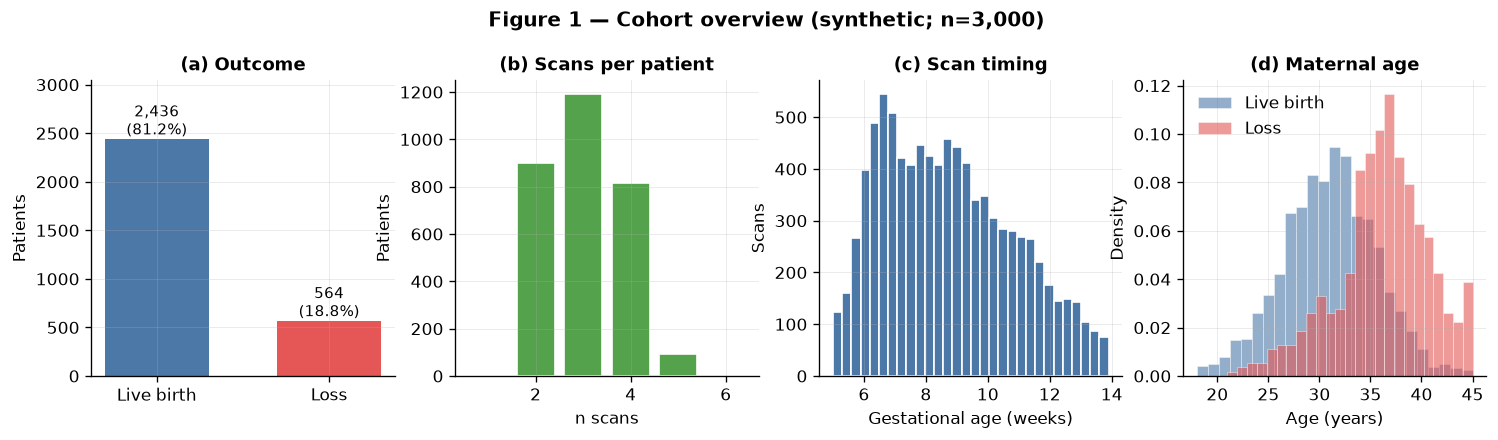

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

# (a) outcome balance
counts = patients_df["label"].value_counts().sort_index()
axes[0].bar(["Live birth", "Loss"], counts.values, color=[C["live"], C["loss"]], width=.6)
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v/n_pat:.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_title("(a) Outcome")
axes[0].set_ylabel("Patients")
axes[0].set_ylim(0, counts.max() * 1.25)

# (b) scans per patient
spp = scans_df.groupby("patient_id").size()
axes[1].hist(spp, bins=range(1, 8), color="#54A24B", edgecolor="white", align="left", rwidth=.8)
axes[1].set_title("(b) Scans per patient")
axes[1].set_xlabel("n scans"); axes[1].set_ylabel("Patients")

# (c) when scans happen
axes[2].hist(scans_df.gestational_age_weeks, bins=30, color="#4C78A8", edgecolor="white")
axes[2].set_title("(c) Scan timing")
axes[2].set_xlabel("Gestational age (weeks)"); axes[2].set_ylabel("Scans")

# (d) maternal age by outcome
for lab, name, col in [(0, "Live birth", C["live"]), (1, "Loss", C["loss"])]:
    axes[3].hist(patients_df.loc[patients_df.label == lab, "age"], bins=25, alpha=.6,
                 label=name, color=col, density=True, edgecolor="white", linewidth=.4)
axes[3].set_title("(d) Maternal age")
axes[3].set_xlabel("Age (years)"); axes[3].set_ylabel("Density"); axes[3].legend()

fig.suptitle(f"Figure 1 — Cohort overview (synthetic; n={n_pat:,})", y=1.06,
             fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig1_cohort_overview.png")
plt.show()

### 2.4 Figure 2 — The signal FETA has to find

Median trajectory of each ultrasound marker against gestational age, split by outcome.
The gap between the two curves *is* the sonographic signal. Note **YSD**: the yolk sac is
**enlarged**, not shrunken, in failing pregnancies — a real and frequently-missed clinical
detail that the generator reproduces.

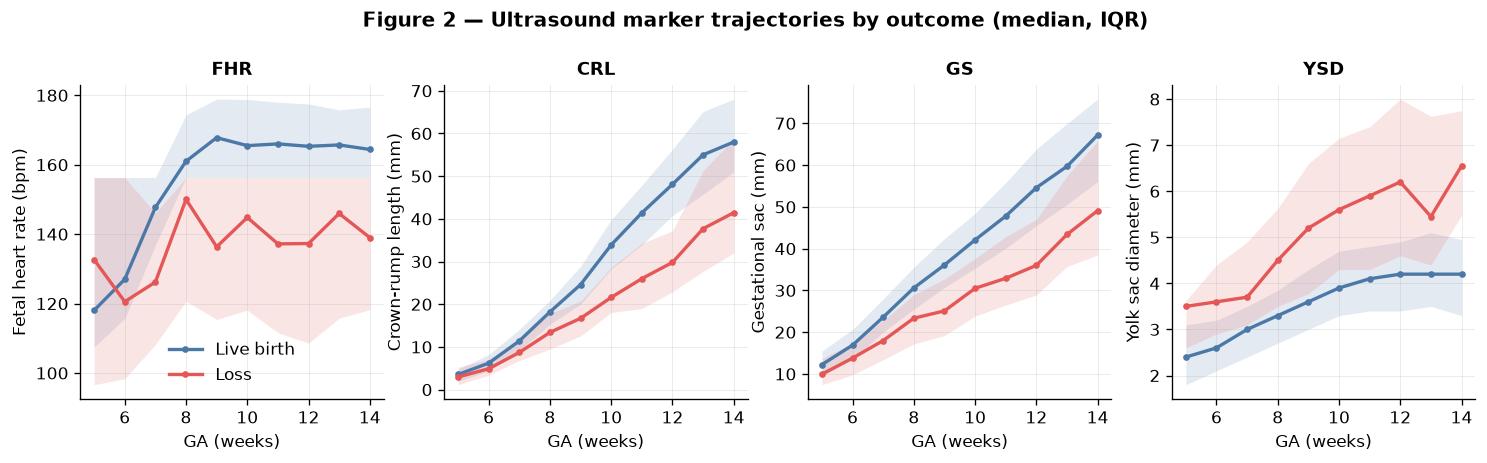

In [4]:
merged = scans_df.merge(patients_df[["patient_id", "label"]], on="patient_id")
merged["ga_bin"] = merged.gestational_age_weeks.round(0)

MARKERS = [("FHR", "Fetal heart rate (bpm)"), ("CRL", "Crown-rump length (mm)"),
           ("GS",  "Gestational sac (mm)"),   ("YSD", "Yolk sac diameter (mm)")]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (m, ylabel) in zip(axes, MARKERS):
    for lab, name, col in [(0, "Live birth", C["live"]), (1, "Loss", C["loss"])]:
        g = (merged[merged.label == lab].groupby("ga_bin")[m]
             .agg(["median", lambda s: s.quantile(.25), lambda s: s.quantile(.75), "size"]))
        g.columns = ["med", "q1", "q3", "n"]
        g = g[g.n >= 10]                      # drop sparse tails
        ax.plot(g.index, g["med"], color=col, lw=2, label=name, marker="o", ms=3)
        ax.fill_between(g.index, g.q1, g.q3, color=col, alpha=.15, lw=0)
    ax.set_title(m); ax.set_xlabel("GA (weeks)"); ax.set_ylabel(ylabel)
axes[0].legend()

fig.suptitle("Figure 2 — Ultrasound marker trajectories by outcome (median, IQR)",
             y=1.06, fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig2_marker_trajectories.png")
plt.show()

### 2.5 Figure 3 — The signal PREG-Net has to find

Loss rate per stratum of each maternal variable — the maternal signal PREG-Net's graph
tower is built to exploit (under input parity it also receives the scan nodes).

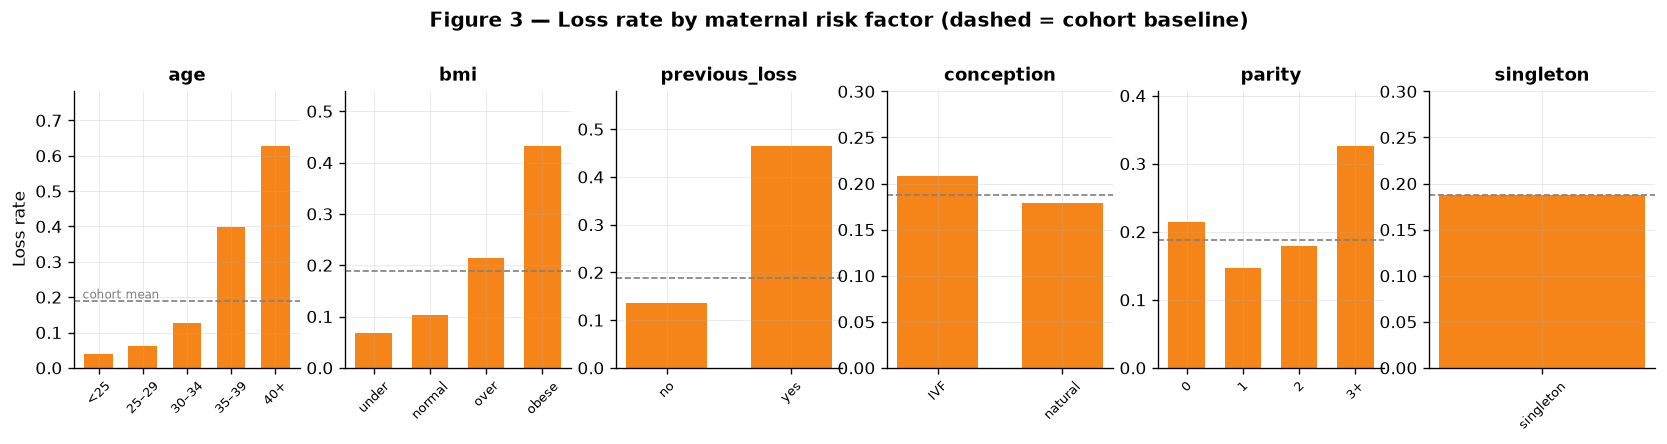

In [5]:
p = patients_df.copy()
p["conception_ivf"] = (p.conception.str.upper() == "IVF").astype(int)

strata = [
    ("age",           pd.cut(p.age,  [0, 25, 30, 35, 40, 99], labels=["<25","25–29","30–34","35–39","40+"])),
    ("bmi",           pd.cut(p.bmi,  [0, 18.5, 25, 30, 99],   labels=["under","normal","over","obese"])),
    ("previous_loss", p.previous_loss.map({0: "no", 1: "yes"})),
    ("conception",    p.conception_ivf.map({0: "natural", 1: "IVF"})),
    ("parity",        p.parity.clip(upper=3).map({0:"0",1:"1",2:"2",3:"3+"})),
    ("singleton",     p.singleton.astype(bool).map({True: "singleton", False: "multiple"})),
]

fig, axes = plt.subplots(1, 6, figsize=(17, 3.0))
base = p.label.mean()
for ax, (name, key) in zip(axes, strata):
    rate = p.groupby(key, observed=True).label.mean()
    ax.bar(rate.index.astype(str), rate.values, color=C["preg"], width=.65)
    ax.axhline(base, ls="--", lw=1, color="grey")
    ax.set_title(name); ax.set_ylabel("Loss rate" if ax is axes[0] else "")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.set_ylim(0, max(rate.max() * 1.25, base * 1.6))
axes[0].text(0.02, base, " cohort mean", color="grey", fontsize=7, va="bottom",
             transform=axes[0].get_yaxis_transform())

fig.suptitle("Figure 3 — Loss rate by maternal risk factor (dashed = cohort baseline)",
             y=1.10, fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig3_maternal_risk.png")
plt.show()

---
## 3. Data processing

Three things happen here, and the order matters for avoiding leakage:

1. **Stratified split** into train / val / test (70 / 15 / 15), preserving the loss rate.
2. **Normalisation statistics fit on the training split only**, then applied to val and
   test. Binary variables are left as 0/1.
3. **Padding** every patient's scan sequence to a fixed length `T=5` with a **mask**, so
   the transformer never attends to padding.

In [6]:
from torch.utils.data import DataLoader
from data.dataset import PregnancyDataset, create_splits, compute_norm_stats, _collate_fn
from data.graph_builder import PatientGraphBuilder, build_knowledge_graph

train_ids, val_ids, test_ids = create_splits(patients_df, seed=SEED)
norm_stats = compute_norm_stats(patients_df, scans_df, train_ids)   # TRAIN ONLY

def make_loader(ids, shuffle, batch_size=32):
    ds = PregnancyDataset(
        patients_df=patients_df[patients_df.patient_id.isin(ids)],
        scans_df=scans_df[scans_df.patient_id.isin(ids)],
        max_scans=5, norm_stats=norm_stats,
    )
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                      collate_fn=_collate_fn, num_workers=0)

loaders = {
    "train": make_loader(train_ids, True),
    "val":   make_loader(val_ids,   False),
    "test":  make_loader(test_ids,  False),
}

for name, ids in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    sub = patients_df[patients_df.patient_id.isin(ids)]
    print(f"{name:5s}: {len(ids):5,} patients | loss rate {sub.label.mean():.1%}")

batch = next(iter(loaders["train"]))
print("\nbatch tensors:")
for k, v in batch.items():
    if torch.is_tensor(v):
        print(f"  {k:20s} {tuple(v.shape)}")

train: 2,099 patients | loss rate 18.8%
val  :   449 patients | loss rate 18.7%
test :   452 patients | loss rate 19.0%

batch tensors:
  temporal_features    (32, 5, 4)
  gestational_ages     (32, 5)
  temporal_mask        (32, 5)
  maternal_features    (32, 7)
  label                (32,)


### 3.1 The knowledge graph (PREG-Net's input)

PREG-Net does not consume a flat feature vector — it consumes a **graph** whose edges
encode known clinical dependencies (e.g. `age → previous_loss`, `bmi → conception`).
Under **input parity** we hand PREG-Net the **full graph** with `include_ultrasound=True`: the **7 maternal nodes plus the per-scan ultrasound nodes**, wired by temporal edges. It sees the same two modalities every other model sees — its only distinction is that it reads them as a *graph*.

In [7]:
clinical_graph_builder = PatientGraphBuilder(max_scans=5, include_ultrasound=False)  # reference only
full_graph_builder     = PatientGraphBuilder(max_scans=5, include_ultrasound=True)   # <- what every graph model gets

g = full_graph_builder.batch_to_graph(batch)
print("Full graph — PREG-Net's input under INPUT PARITY (maternal + ultrasound nodes)")
print(f"  node_features {tuple(g['node_features'].shape)}   (batch, nodes, feat)")
print(f"  edge_index    {tuple(g['edge_index'].shape)}   ({g['edge_index'].shape[1]} edges)")
print(f"  node_types    {tuple(g['node_types'].shape)}")

g_clin = clinical_graph_builder.batch_to_graph(batch)
print(f"\nFor contrast, the clinical-only graph (NOT used in this notebook) has "
      f"{g_clin['node_features'].shape[1]} nodes (maternal only) and "
      f"{g_clin['edge_index'].shape[1]} edges — that is the handicap the input-parity rule forbids.")


Full graph — PREG-Net's input under INPUT PARITY (maternal + ultrasound nodes)
  node_features (32, 27, 1)   (batch, nodes, feat)
  edge_index    (2, 167)   (167 edges)
  node_types    (27,)

For contrast, the clinical-only graph (NOT used in this notebook) has 7 nodes (maternal only) and 24 edges — that is the handicap the input-parity rule forbids.


### 3.2 Figure 4 — Architecture schematic

The three models, and what each one is allowed to see.

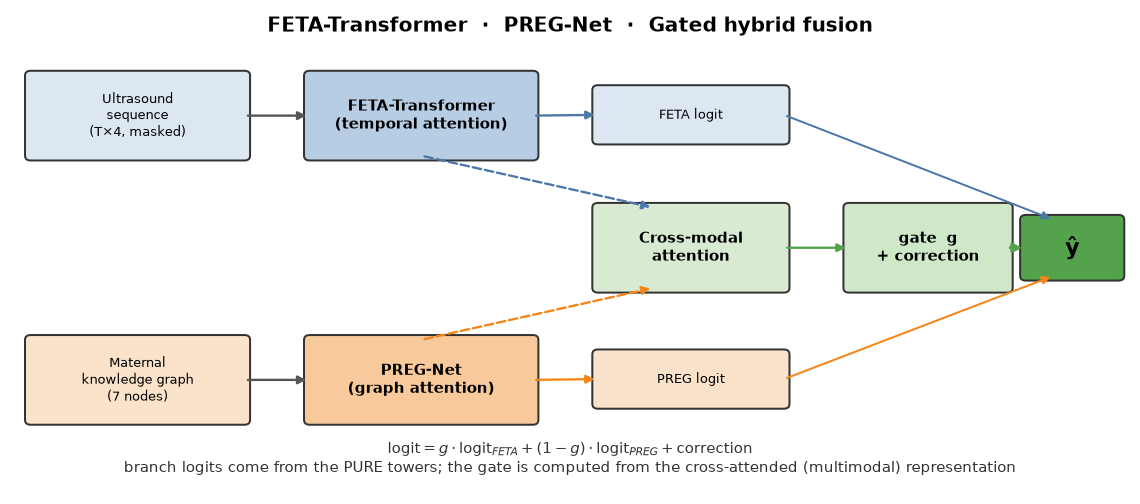

In [8]:
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.axis("off"); ax.grid(False)

def box(x, y, w, h, text, fc, ec="#333", fs=9, weight="normal"):
    ax.add_patch(mpl.patches.FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.06", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, weight=weight)

def arrow(x1, y1, x2, y2, style="-|>", col="#555", lw=1.4, ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=col, lw=lw, linestyle=ls,
                                shrinkA=2, shrinkB=2))

# inputs
box(0.2, 4.2, 2.3, 1.0, "Ultrasound\nsequence\n(T×4, masked)", "#DCE7F2", fs=8)
box(0.2, 0.9, 2.3, 1.0, "Maternal\nknowledge graph\n(7 nodes)",  "#FBE3CB", fs=8)

# towers
box(3.2, 4.2, 2.4, 1.0, "FETA-Transformer\n(temporal attention)", "#B7CDE4", fs=9, weight="bold")
box(3.2, 0.9, 2.4, 1.0, "PREG-Net\n(graph attention)",            "#F7C99B", fs=9, weight="bold")

arrow(2.5, 4.7, 3.2, 4.7); arrow(2.5, 1.4, 3.2, 1.4)

# cross-attention
box(6.3, 2.55, 2.0, 1.0, "Cross-modal\nattention", "#D9EAD3", fs=9, weight="bold")
arrow(4.4, 4.2, 6.9, 3.55, col="#4C78A8", ls="--")
arrow(4.4, 1.9, 6.9, 2.55, col="#F58518", ls="--")

# branch logits (from PURE reps)
box(6.3, 4.4, 2.0, 0.62, "FETA logit", "#DCE7F2", fs=8)
box(6.3, 1.1, 2.0, 0.62, "PREG logit", "#FBE3CB", fs=8)
arrow(5.6, 4.7, 6.3, 4.71, col="#4C78A8")
arrow(5.6, 1.4, 6.3, 1.41, col="#F58518")

# gate
box(9.0, 2.55, 1.7, 1.0, "gate  g\n+ correction", "#CFE8C8", fs=9, weight="bold")
arrow(8.3, 3.05, 9.0, 3.05, col="#54A24B")

# fused output
box(9.0, 4.4, 1.7, 0.62, "", "#FFFFFF", ec="#FFFFFF")
box(10.9, 2.7, 1.0, 0.7, "ŷ", "#54A24B", fs=13, weight="bold")
arrow(8.3, 4.71, 11.2, 3.4, col="#4C78A8", lw=1.2)
arrow(8.3, 1.41, 11.2, 2.7,  col="#F58518", lw=1.2)
arrow(10.7, 3.05, 10.9, 3.05, col="#54A24B", lw=2)

ax.text(6.0, 5.75, "FETA-Transformer  ·  PREG-Net  ·  Gated hybrid fusion",
        ha="center", fontsize=12, weight="bold")
ax.text(6.0, 0.25,
        r"$\mathrm{logit} = g \cdot \mathrm{logit}_{FETA} + (1-g)\cdot \mathrm{logit}_{PREG}"
        r" + \mathrm{correction}$" "\n"
        "branch logits come from the PURE towers; the gate is computed from the "
        "cross-attended (multimodal) representation",
        ha="center", fontsize=9, color="#333")

fig.savefig(FIGDIR / "fig4_architecture.png")
plt.show()

---
## 4. Train the two towers — on the same full inputs

A shared helper so all three models are trained under identical conditions — same loss
(`BCEWithLogitsLoss` with `pos_weight = n_neg/n_pos`), same optimiser, same early stopping
on **validation AUROC**. Crucially they also train on **identical inputs** — every model receives both `patients.csv` and `scans.csv`. No model is denied a modality; the only thing that differs between them is *architecture*.

In [9]:
from utils.training import Trainer, compute_class_weights
from utils.metrics import compute_all_metrics
from models import FETATransformer, PREGNet, HybridFusionPredictor

train_labels = loaders["train"].dataset.patients["label"].to_numpy()
POS_WEIGHT   = compute_class_weights(train_labels)
EPOCHS       = 60
print(f"pos_weight = {POS_WEIGHT:.2f}")

@torch.no_grad()
def evaluate(trainer, loader):
    '''Return (metrics, y_true, y_prob) on a loader using the trainer's batch unpacking.'''
    trainer.model.eval()
    probs, labs = [], []
    for b in loader:
        inputs, y = trainer._unpack_batch(b)
        out = trainer.model(**inputs)
        logits = out["logits"] if isinstance(out, dict) else (out[0] if isinstance(out, tuple) else out)
        probs.append(torch.sigmoid(logits.squeeze(-1)).cpu().numpy())
        labs.append(y.cpu().numpy())
    y_prob = np.concatenate(probs); y_true = np.concatenate(labs)
    return compute_all_metrics(y_true, y_prob), y_true, y_prob

def run(name, model, collate_mode, graph_builder=None, aux=0.0, epochs=EPOCHS):
    print(f"\n{'='*64}\nTraining {name}\n{'='*64}")
    t = Trainer(model=model, train_loader=loaders["train"], val_loader=loaders["val"],
                lr=1e-3, weight_decay=1e-4, pos_weight=POS_WEIGHT, patience=15,
                checkpoint_dir=str(ROOT / "results" / "notebook" / name / "checkpoints"),
                device=DEVICE, collate_mode=collate_mode,
                graph_builder=graph_builder, aux_loss_weight=aux)
    t.fit(epochs)
    ckpt = Path(t.checkpoint_dir) / "best_model.pt"
    if ckpt.exists():
        t.load_checkpoint(str(ckpt))          # restore best-val-AUROC weights
    m, y_true, y_prob = evaluate(t, loaders["test"])
    print(f"\n{name} — TEST AUROC {m['auroc']:.4f} | AUPRC {m['auprc']:.4f} | "
          f"sens {m['sensitivity']:.3f} | spec {m['specificity']:.3f}")
    return {"name": name, "trainer": t, "history": pd.DataFrame(t.history),
            "metrics": m, "y_true": y_true, "y_prob": y_prob}

import logging; logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
RESULTS = {}

pos_weight = 4.33


### 4.1 FETA-Transformer — the **scan tower**

Attends over the irregularly-spaced scan sequence. Continuous positional encoding on
gestational age (not step index), so a scan at 7.2 weeks and one at 9.8 weeks are placed
correctly in time. It also receives the 7 maternal variables through a cross-attention block (input parity), but its inductive bias is built around the **scan trajectory**.

In [10]:
RESULTS["feta"] = run("feta", FETATransformer(), collate_mode="feta")

Using device: cpu



Training feta


Starting training for up to 60 epochs
Epoch   1/60 | train_loss=0.7603  val_loss=0.5184 | val_AUROC=0.8787  val_AUPRC=0.8499 | 3.9s
Saved checkpoint at epoch 1 (AUROC=0.8787) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\feta\checkpoints\best_model.pt
Epoch   2/60 | train_loss=0.6532  val_loss=0.4922 | val_AUROC=0.8828  val_AUPRC=0.8505 | 3.6s
Saved checkpoint at epoch 2 (AUROC=0.8828) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\feta\checkpoints\best_model.pt
Epoch   3/60 | train_loss=0.6235  val_loss=0.4944 | val_AUROC=0.8999  val_AUPRC=0.8604 | 3.5s
Saved checkpoint at epoch 3 (AUROC=0.8999) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\feta\checkpoints\best_model.pt
Epoch   4/60 | train_loss=0.6177  val_loss=0.4981 | val_AUROC=0.8867  val_AUPRC=0.8537 | 3.3s
Epoch   5/60 | train_loss=0.6328  val_loss=0.4917 | val_AUROC=0.8986  val_AUPRC=0.8611 | 3.3s
Epoch   6/60 | train_loss=0.5882  val_loss=0.4926 | val_AUROC=0.8950  val_AUPRC=0.86


feta — TEST AUROC 0.9141 | AUPRC 0.8663 | sens 0.767 | spec 0.989


### 4.2 PREG-Net — the **maternal tower** (graph attention)

Graph attention over the knowledge graph. Under input parity we build it with `include_ultrasound=True`, so its graph carries the **ultrasound nodes alongside the 7 maternal nodes** — it sees both modalities, just as FETA does. What differs is the inductive bias: PREG-Net treats every variable as a **peer node** in a graph.

In [11]:
RESULTS["preg"] = run("preg", PREGNet(), collate_mode="preg",
                      graph_builder=full_graph_builder)

Using device: cpu
Starting training for up to 60 epochs



Training preg


Epoch   1/60 | train_loss=0.8338  val_loss=0.3628 | val_AUROC=0.9790  val_AUPRC=0.9307 | 3.7s
Saved checkpoint at epoch 1 (AUROC=0.9790) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\preg\checkpoints\best_model.pt
Epoch   2/60 | train_loss=0.5489  val_loss=0.2695 | val_AUROC=0.9850  val_AUPRC=0.9486 | 4.0s
Saved checkpoint at epoch 2 (AUROC=0.9850) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\preg\checkpoints\best_model.pt
Epoch   3/60 | train_loss=0.5369  val_loss=0.2404 | val_AUROC=0.9900  val_AUPRC=0.9633 | 4.0s
Saved checkpoint at epoch 3 (AUROC=0.9900) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\preg\checkpoints\best_model.pt
Epoch   4/60 | train_loss=0.4608  val_loss=0.2446 | val_AUROC=0.9916  val_AUPRC=0.9683 | 3.5s
Saved checkpoint at epoch 4 (AUROC=0.9916) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\preg\checkpoints\best_model.pt
Epoch   5/60 | train_loss=0.4427  val_loss=0.2063 | val_AUROC=0.9914  val_AUPRC=


preg — TEST AUROC 0.9938 | AUPRC 0.9782 | sens 0.919 | spec 0.978


### 4.3 Figure 5 — Tower training curves

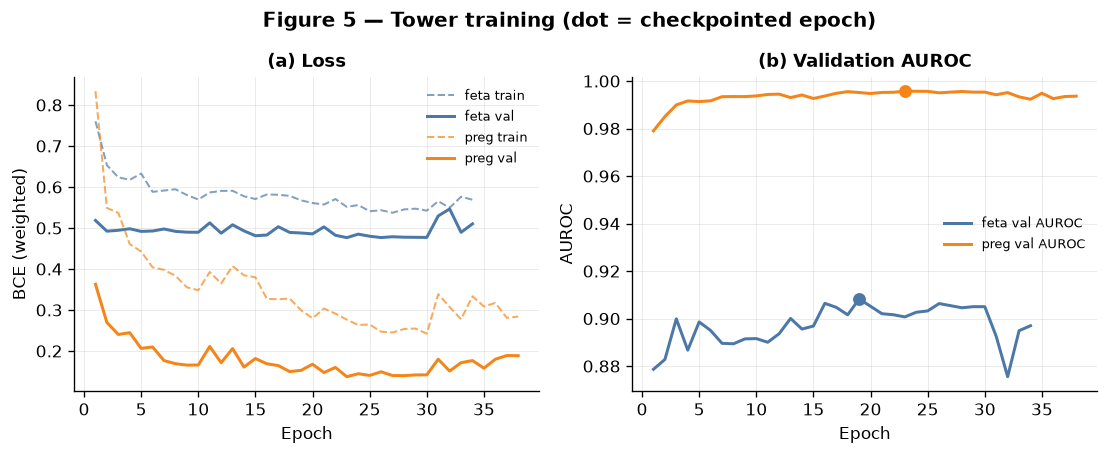

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for key, col in [("feta", C["feta"]), ("preg", C["preg"])]:
    h = RESULTS[key]["history"]
    axes[0].plot(h.epoch, h.train_loss, color=col, ls="--", lw=1.2, alpha=.7,
                 label=f"{key} train")
    axes[0].plot(h.epoch, h.val_loss,   color=col, lw=1.8, label=f"{key} val")
    axes[1].plot(h.epoch, h.val_auroc,  color=col, lw=1.8, label=f"{key} val AUROC")
    best = h.val_auroc.idxmax()
    axes[1].scatter(h.epoch[best], h.val_auroc[best], color=col, s=45, zorder=5)

axes[0].set_title("(a) Loss");      axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE (weighted)")
axes[1].set_title("(b) Validation AUROC"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.suptitle("Figure 5 — Tower training (dot = checkpointed epoch)",
             y=1.04, fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig5_specialist_training.png")
plt.show()

---
## 5. Train the hybrid

### How the two halves become one number

The towers do **not** each produce half an answer. Each produces a *complete* prediction —
its own logit — and the hybrid learns, **per patient**, which one to trust:

$$\text{logit} \;=\; g(x)\cdot \text{logit}_{\text{FETA}} \;+\; \bigl(1-g(x)\bigr)\cdot \text{logit}_{\text{PREG}} \;+\; \text{correction}(x)$$

Three things make this more than an average:

1. **`g` is not fixed at 0.5.** It is the output of a small network, recomputed for *every
   patient*. It can be 0.9 for one and 0.1 for the next.
2. **`g` is decided by a network that has seen *both* modalities** — the cross-attention
   block lets scan tokens and clinical nodes attend to each other, and it is that fused
   representation which drives the gate.
3. **The `correction` term is unconstrained**, so the fused logit can fall *outside* the
   range of the two branch logits — the model can say "neither tower is individually
   alarmed, but the *combination* is."

The subtlety: the **branch logits come from each tower's own PRE-fusion representation**. Both towers see the same full inputs, but through different inductive biases — a temporal transformer vs. a graph. The gate therefore routes, per patient, between two *architectures'* readings of the same data; only the routing decision draws on the cross-attended, fused representation.

An **auxiliary per-branch loss** (`aux_loss_weight=0.3`) keeps both towers individually
predictive during joint training.

In [13]:
RESULTS["hybrid"] = run(
    "hybrid",
    HybridFusionPredictor(gated=True),      # per-patient gate routing
    collate_mode="ensemble",
    graph_builder=full_graph_builder,       # every tower sees both modalities (input parity)
    aux=0.3,                                # anti-collapse auxiliary loss
    epochs=80,
)

Using device: cpu
Starting training for up to 80 epochs



Training hybrid


Epoch   1/80 | train_loss=1.3498  val_loss=0.3650 | val_AUROC=0.9781  val_AUPRC=0.9459 | 6.9s
Saved checkpoint at epoch 1 (AUROC=0.9781) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\hybrid\checkpoints\best_model.pt
Epoch   2/80 | train_loss=0.9642  val_loss=0.2471 | val_AUROC=0.9916  val_AUPRC=0.9710 | 6.5s
Saved checkpoint at epoch 2 (AUROC=0.9916) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\hybrid\checkpoints\best_model.pt
Epoch   3/80 | train_loss=0.8122  val_loss=0.1896 | val_AUROC=0.9939  val_AUPRC=0.9766 | 6.2s
Saved checkpoint at epoch 3 (AUROC=0.9939) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\hybrid\checkpoints\best_model.pt
Epoch   4/80 | train_loss=0.7795  val_loss=0.1559 | val_AUROC=0.9954  val_AUPRC=0.9838 | 6.3s
Saved checkpoint at epoch 4 (AUROC=0.9954) -> c:\Users\sakth\OneDrive\Desktop\Preg-Feta\results\notebook\hybrid\checkpoints\best_model.pt
Epoch   5/80 | train_loss=0.6511  val_loss=0.1532 | val_AUROC=0.9964  va


hybrid — TEST AUROC 0.9975 | AUPRC 0.9886 | sens 0.977 | spec 0.981


### 5.1 A late-fusion reference (computed, not trained)

The honesty control: we do **not** train a fourth model — we take the two towers' own
logits and simply **average them**. If the gated hybrid cannot beat this trivial fusion,
the architecture is not earning its keep.

In [14]:
# Plain logit-average of the two towers — the honesty control (NOT a trained model).
# Recover each tower's logit from its stored probability, average, re-sigmoid.
def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

_yt   = RESULTS["feta"]["y_true"]
_pavg = 1.0 / (1.0 + np.exp(-0.5 * (_logit(RESULTS["feta"]["y_prob"])
                                    + _logit(RESULTS["preg"]["y_prob"]))))
RESULTS["ensemble"] = {"name": "ensemble",
                       "metrics": compute_all_metrics(_yt, _pavg),
                       "y_true": _yt, "y_prob": _pavg}
print(f"logit-average reference — TEST AUROC {RESULTS['ensemble']['metrics']['auroc']:.4f} "
      f"| AUPRC {RESULTS['ensemble']['metrics']['auprc']:.4f}")

logit-average reference — TEST AUROC 0.9944 | AUPRC 0.9792


---
## 6. Comparison — held-out test set

### 6.1 Figure 6 — ROC and precision–recall

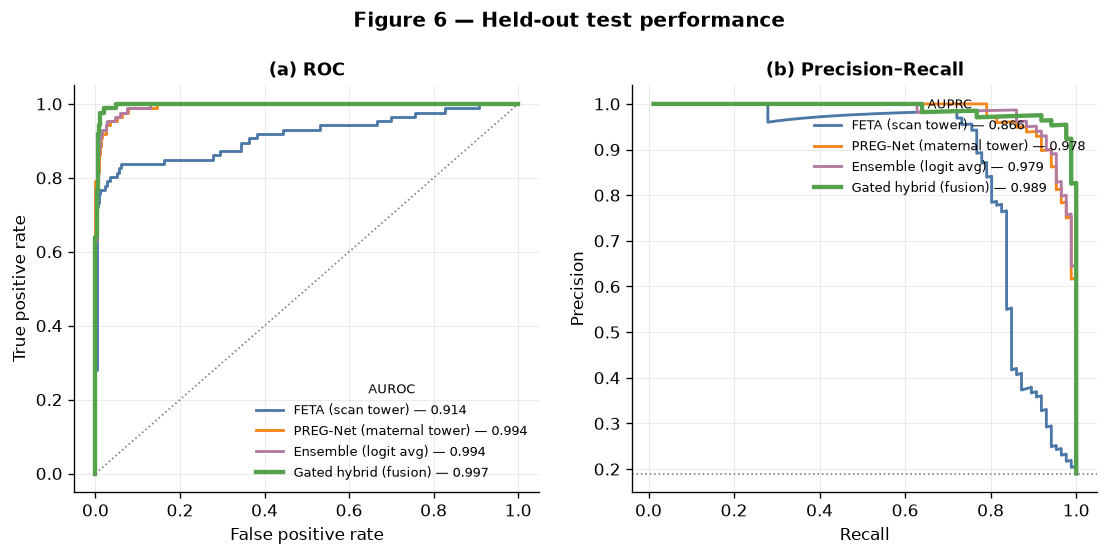

In [15]:
def roc_curve_np(y, p):
    o = np.argsort(-p); y = y[o]
    tp = np.cumsum(y); fp = np.cumsum(1 - y)
    tpr = np.r_[0, tp / max(y.sum(), 1)]; fpr = np.r_[0, fp / max((1 - y).sum(), 1)]
    return fpr, tpr

def pr_curve_np(y, p):
    o = np.argsort(-p); y = y[o]
    tp = np.cumsum(y); k = np.arange(1, len(y) + 1)
    return tp / max(y.sum(), 1), tp / k          # recall, precision

ORDER = [("feta", "FETA (scan tower)", C["feta"]),
         ("preg", "PREG-Net (maternal tower)", C["preg"]),
         ("ensemble", "Ensemble (logit avg)",  C["ens"]),
         ("hybrid", "Gated hybrid (fusion)",   C["hybrid"])]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for key, label, col in ORDER:
    r = RESULTS[key]
    lw = 2.6 if key == "hybrid" else 1.7
    fpr, tpr = roc_curve_np(r["y_true"], r["y_prob"])
    axes[0].plot(fpr, tpr, color=col, lw=lw, label=f"{label} — {r['metrics']['auroc']:.3f}")
    rec, prec = pr_curve_np(r["y_true"], r["y_prob"])
    axes[1].plot(rec, prec, color=col, lw=lw, label=f"{label} — {r['metrics']['auprc']:.3f}")

axes[0].plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
axes[0].set_title("(a) ROC"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].legend(loc="lower right", fontsize=8, title="AUROC", title_fontsize=8)

base = RESULTS["feta"]["y_true"].mean()
axes[1].axhline(base, ls=":", color="grey", lw=1)
axes[1].set_title("(b) Precision–Recall"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=8, title="AUPRC", title_fontsize=8)

fig.suptitle("Figure 6 — Held-out test performance", y=1.02, fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig6_roc_pr.png")
plt.show()

### 6.2 Test-set metric table

In [16]:
rows = []
for key, label, _ in ORDER:
    m = RESULTS[key]["metrics"]
    rows.append({"Model": label, "AUROC": m["auroc"], "AUPRC": m["auprc"],
                 "Accuracy": m["accuracy"], "Sensitivity": m["sensitivity"],
                 "Specificity": m["specificity"], "F1": m["f1"]})
test_table = pd.DataFrame(rows).set_index("Model").round(4)
test_table

,AUROC,AUPRC,Accuracy,Sensitivity,Specificity,F1
Model,,,,,,
FETA (scan tower),0.9141,0.8663,0.9469,0.7674,0.9891,0.8462
PREG-Net (maternal tower),0.9938,0.9782,0.9668,0.9186,0.9781,0.9133
Ensemble (logit avg),0.9944,0.9792,0.9712,0.9186,0.9836,0.9240
Gated hybrid (fusion),0.9975,0.9886,0.9801,0.9767,0.9809,0.9492


---
## 7. Cross-validated results — the numbers for the paper

A single split is noisy. The manuscript reports **5-fold stratified cross-validation**,
produced by `scripts/cross_validate.py` **on the dual-etiology cohort**. This section reads
those results — it does not retrain.

```bash
.venv/Scripts/python.exe scripts/cross_validate.py \
    --patients-csv data/generated_dual/patients.csv \
    --scans-csv    data/generated_dual/scans.csv \
    --out-dir      results/cv_dual_full \
    --hybrid-gated --n-folds 5   # NO --clinical-only: every model sees both modalities
```

> `results/cv_kaggle/` holds the **old v1 single-etiology** cross-validation and is *not*
> read here. Its numbers (hybrid 0.888, PREG-Net 0.630) describe a different cohort and
> must not be mixed with the ones below.


In [17]:
CV_DIR = ROOT / "results" / "cv_dual_full"   # input-parity CV (dual cohort, NO --clinical-only)
cv_path = CV_DIR / "fold_metrics.csv"

if not cv_path.exists():
    raise FileNotFoundError(
        f"No cross-validation results at {cv_path}.\n"
        "Run the scripts/cross_validate.py command in the cell above first "
        "(it must be the --out-dir results/cv_dual_full run — WITHOUT --clinical-only)."
    )

cv = pd.read_csv(cv_path)
cv_test = cv[cv.split == "test"]
cv_test = cv_test[cv_test.model.isin(["feta", "preg", "hybrid", "ensemble"])]  # 3 models + logit-avg reference

PRETTY = {
    "feta": "FETA (scan tower)", "preg": "PREG-Net (maternal tower)",
    "hybrid": "Gated hybrid (fusion)", "ensemble": "Ensemble (logit avg)",
}

summary = (cv_test.groupby("model")
           .agg(n_folds=("fold", "nunique"),
                auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"),
                auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std"),
                sens_mean=("sensitivity", "mean"), spec_mean=("specificity", "mean"))
           .sort_values("auroc_mean", ascending=False))
summary.index = [PRETTY.get(i, i) for i in summary.index]

paper_table = pd.DataFrame({
    "Test AUROC": [f"{r.auroc_mean:.3f} ± {r.auroc_std:.3f}" for r in summary.itertuples()],
    "Test AUPRC": [f"{r.auprc_mean:.3f} ± {r.auprc_std:.3f}" for r in summary.itertuples()],
    "Sensitivity": [f"{r.sens_mean:.3f}" for r in summary.itertuples()],
    "Specificity": [f"{r.spec_mean:.3f}" for r in summary.itertuples()],
    "Folds": [int(r.n_folds) for r in summary.itertuples()],
}, index=summary.index)
paper_table.index.name = "Model"

print(f"5-fold cross-validation — {SOURCE}\n")
paper_table

5-fold cross-validation — local copy (data\generated_dual)



,Test AUROC,Test AUPRC,Sensitivity,Specificity,Folds
Model,,,,,
Ensemble (logit avg),0.989 ± 0.006,0.976 ± 0.012,0.926,0.985,5
Gated hybrid (fusion),0.988 ± 0.004,0.972 ± 0.006,0.943,0.975,5
PREG-Net (maternal tower),0.981 ± 0.006,0.958 ± 0.013,0.902,0.976,5
FETA (scan tower),0.884 ± 0.014,0.844 ± 0.017,0.739,0.981,5


### 7.1 Figure 7 — Cross-validated AUROC, with fold spread

The bar is the mean across folds; the error bar is ±1 SD; the dots are the individual folds.
**Read the dots.** If the fold-to-fold spread of a model overlaps its neighbour, the two are
not distinguishable, however different the means look.

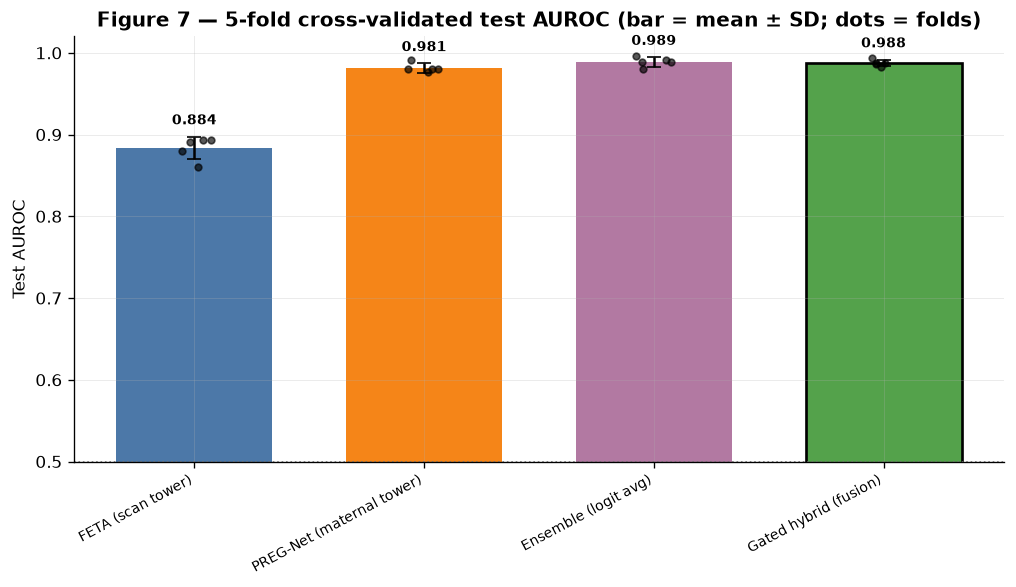

In [18]:
KEY_MODELS = ["feta", "preg", "ensemble", "hybrid"]
COLMAP = {"feta": C["feta"], "preg": C["preg"],
          "ensemble": C["ens"], "hybrid": C["hybrid"]}

present = [m for m in KEY_MODELS if m in set(cv_test.model)]
stats = (cv_test[cv_test.model.isin(present)].groupby("model")
         .auroc.agg(["mean", "std"]).reindex(present))

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(present))
ax.bar(x, stats["mean"], yerr=stats["std"].fillna(0), capsize=4, width=.68,
       color=[COLMAP[m] for m in present],
       edgecolor=["black" if m == "hybrid" else "none" for m in present],
       linewidth=[1.6 if m == "hybrid" else 0 for m in present])

for i, m in enumerate(present):                    # individual folds
    f = cv_test[cv_test.model == m].auroc.values
    ax.scatter(np.full_like(f, i, dtype=float) + np.random.uniform(-.08, .08, len(f)),
               f, color="black", s=16, zorder=5, alpha=.65)
    ax.text(i, stats["mean"].iloc[i] + (stats["std"].fillna(0).iloc[i]) + .015,
            f"{stats['mean'].iloc[i]:.3f}", ha="center", fontsize=8.5, weight="bold")

ax.set_xticks(x)
ax.set_xticklabels([PRETTY.get(m, m) for m in present], rotation=28, ha="right", fontsize=8.5)
ax.set_ylabel("Test AUROC")
ax.set_ylim(0.5, 1.02)
ax.axhline(0.5, ls=":", color="grey", lw=1)
ax.set_title("Figure 7 — 5-fold cross-validated test AUROC (bar = mean ± SD; dots = folds)",
             fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig7_cv_auroc.png")
plt.show()

### 7.2 Figure 8 — Does the hybrid beat the single towers *on every fold*?

A mean can hide a model that wins on average by winning big on one fold. This is the
paired, per-fold view: hybrid minus each single tower. Bars above zero = the hybrid won
that fold.

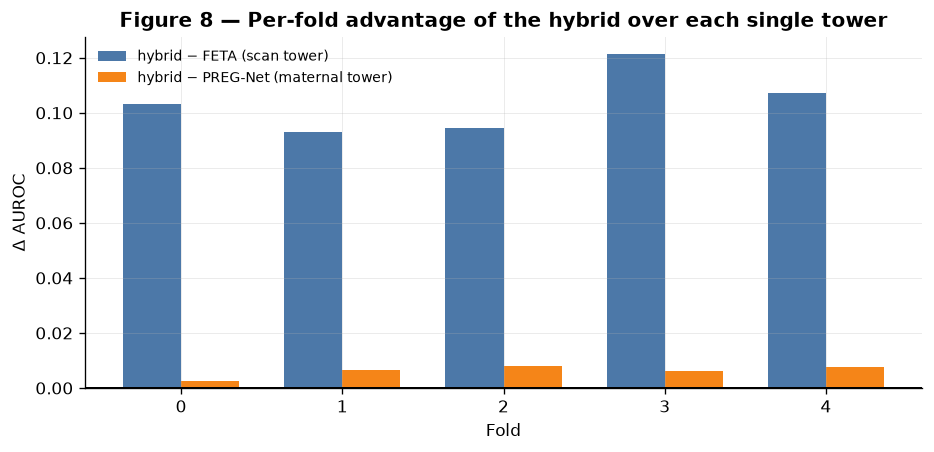

hybrid − feta     : mean Δ = +0.1038 | won 5/5 folds
hybrid − preg     : mean Δ = +0.0062 | won 5/5 folds
hybrid − ensemble : mean Δ = -0.0013 | won 1/5 folds


In [19]:
piv = cv_test.pivot_table(index="fold", columns="model", values="auroc")

fig, ax = plt.subplots(figsize=(9, 3.8))
folds = piv.index.values
w = 0.36
for i, (spec, col) in enumerate([("feta", C["feta"]), ("preg", C["preg"])]):
    if spec not in piv or "hybrid" not in piv:
        continue
    delta = piv["hybrid"] - piv[spec]
    ax.bar(folds + (i - .5) * w, delta, width=w, color=col,
           label=f"hybrid − {PRETTY[spec]}")

ax.axhline(0, color="black", lw=1.2)
ax.set_xticks(folds); ax.set_xlabel("Fold"); ax.set_ylabel("Δ AUROC")
ax.set_title("Figure 8 — Per-fold advantage of the hybrid over each single tower",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=8.5)
fig.savefig(FIGDIR / "fig8_per_fold_delta.png")
plt.show()

if "hybrid" in piv:
    for spec in ["feta", "preg", "ensemble"]:
        if spec in piv:
            d = piv["hybrid"] - piv[spec]
            print(f"hybrid − {spec:9s}: mean Δ = {d.mean():+.4f} | "
                  f"won {int((d > 0).sum())}/{len(d)} folds")

### 7.3 The verdict — computed, not asserted

The temptation in a fusion paper is to compare the hybrid only against the two towers it fuses. Under **input parity** those towers already see the same full data, so a hybrid–tower gap could just be the difference between one architecture and two — it is *not* the test that matters.

The comparisons that actually decide whether the architecture is worth anything:

- **hybrid vs. the plain logit-average ensemble** — same two towers, trivial fusion. If the
  gate is not beating this, the gate is not doing anything.
- **hybrid vs. the best off-the-shelf baseline** — a gradient-boosted tree or logistic
  regression handed all the raw features. If a tree matches the hybrid, no architectural
  claim survives.

The cell below computes both, compares each gap against the hybrid's own fold-to-fold
standard deviation, and prints the honest conclusion.

In [20]:
piv = cv_test.pivot_table(index="fold", columns="model", values="auroc")
hyb = piv["hybrid"]
hyb_sd = hyb.std()

print(f"Hybrid: {hyb.mean():.4f} ± {hyb_sd:.4f}  (mean ± SD over {len(hyb)} folds)\n")

def verdict(other, tag):
    d = hyb - piv[other]
    wins = int((d > 0).sum())
    beats = "YES" if abs(d.mean()) > hyb_sd else "NO — inside the hybrid's own fold noise"
    print(f"vs {tag:28s} {piv[other].mean():.4f} | "
          f"Δ = {d.mean():+.4f} | won {wins}/{len(d)} folds | "
          f"larger than hybrid SD? {beats}")

for spec in ["feta", "preg"]:
    if spec in piv:
        verdict(spec, PRETTY[spec])
print()
if "ensemble" in piv:
    verdict("ensemble", "plain logit average")

print("\n" + "-" * 72)
if "ensemble" in piv and (hyb - piv["ensemble"]).mean() > hyb_sd:
    print("DEFENSIBLE: the gated fusion beats a plain logit average of the same two towers\n"
          "by more than its own fold-to-fold SD.")
else:
    print("NOT DEFENSIBLE: the hybrid's margin over the plain logit average is smaller than its\n"
          "own fold-to-fold SD. On this cohort you may report that fusion improves on the\n"
          "single-modality towers, but you may NOT claim the gated architecture beats a trivial\n"
          "average. (The off-the-shelf tree / logistic-regression comparison lives in\n"
          "scripts/compare_models.py.)")
print("-" * 72)

Hybrid: 0.9876 ± 0.0042  (mean ± SD over 5 folds)

vs FETA (scan tower)            0.8837 | Δ = +0.1038 | won 5/5 folds | larger than hybrid SD? YES
vs PREG-Net (maternal tower)    0.9813 | Δ = +0.0062 | won 5/5 folds | larger than hybrid SD? YES

vs plain logit average          0.9889 | Δ = -0.0013 | won 1/5 folds | larger than hybrid SD? NO — inside the hybrid's own fold noise

------------------------------------------------------------------------
NOT DEFENSIBLE: the hybrid's margin over the plain logit average is smaller than its
own fold-to-fold SD. On this cohort you may report that fusion improves on the
single-modality towers, but you may NOT claim the gated architecture beats a trivial
average. (The off-the-shelf tree / logistic-regression comparison lives in
scripts/compare_models.py.)
------------------------------------------------------------------------


---
## 8. Interpretability — what the models actually attend to

### 8.1 Figure 9 — The gate

The distribution of `g` across test patients. This is the direct evidence for whether the
hybrid is *routing* (a spread of gate values — different patients trust different towers)
or has simply **collapsed onto one tower** (all mass at 0 or 1) or **degenerated into a
plain average** (all mass at 0.5). Which of the three it is determines whether the fusion
architecture is doing anything at all.

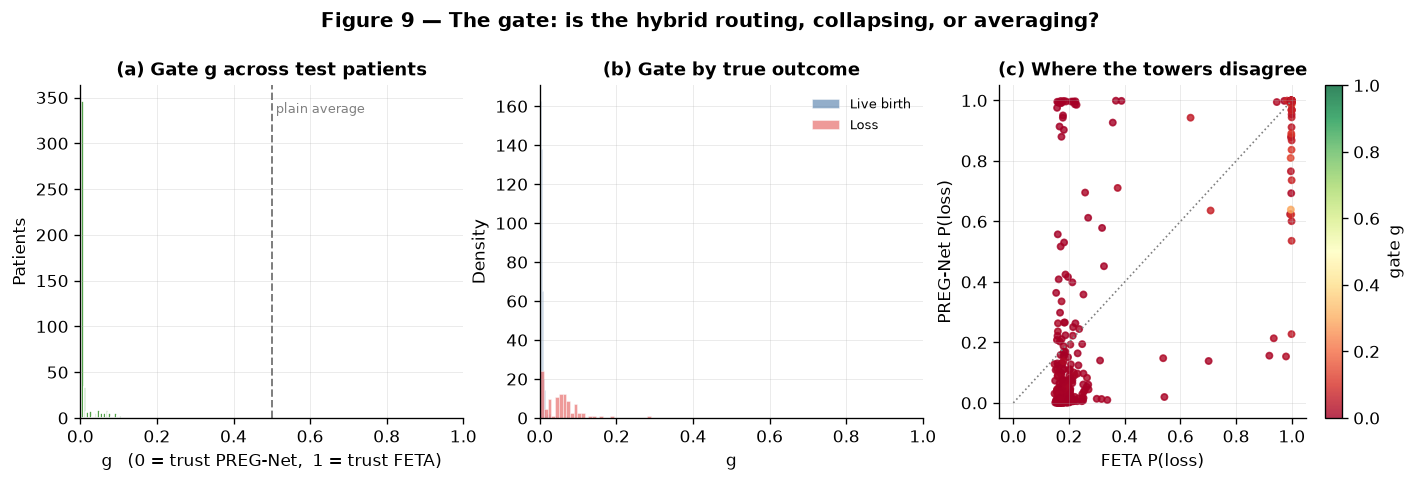

gate: mean 0.015 | sd 0.028 | min 0.002 | max 0.289
share of patients with g outside [0.4, 0.6]: 100.0%


In [21]:
@torch.no_grad()
def collect_hybrid_internals(trainer, loader):
    trainer.model.eval()
    gates, y, p_f, p_p, p_h = [], [], [], [], []
    for b in loader:
        inputs, lab = trainer._unpack_batch(b)
        out = trainer.model(**inputs)
        gates.append(out["fusion_weights"].squeeze(-1).cpu().numpy())
        p_f.append(torch.sigmoid(out["feta_logits"].squeeze(-1)).cpu().numpy())
        p_p.append(torch.sigmoid(out["preg_logits"].squeeze(-1)).cpu().numpy())
        p_h.append(torch.sigmoid(out["logits"].squeeze(-1)).cpu().numpy())
        y.append(lab.cpu().numpy())
    return (np.concatenate(gates), np.concatenate(y),
            np.concatenate(p_f), np.concatenate(p_p), np.concatenate(p_h))

gate, y_h, pf, pp, ph = collect_hybrid_internals(RESULTS["hybrid"]["trainer"], loaders["test"])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

axes[0].hist(gate, bins=40, color=C["hybrid"], edgecolor="white")
axes[0].axvline(0.5, ls="--", color="grey", lw=1.2)
axes[0].text(0.5, axes[0].get_ylim()[1] * .95, " plain average", fontsize=8, color="grey", va="top")
axes[0].set_title("(a) Gate g across test patients")
axes[0].set_xlabel("g   (0 = trust PREG-Net,  1 = trust FETA)"); axes[0].set_ylabel("Patients")
axes[0].set_xlim(0, 1)

for lab, name, col in [(0, "Live birth", C["live"]), (1, "Loss", C["loss"])]:
    axes[1].hist(gate[y_h == lab], bins=30, alpha=.6, density=True, label=name,
                 color=col, edgecolor="white", linewidth=.4)
axes[1].set_title("(b) Gate by true outcome")
axes[1].set_xlabel("g"); axes[1].set_ylabel("Density"); axes[1].legend(fontsize=8)
axes[1].set_xlim(0, 1)

sc = axes[2].scatter(pf, pp, c=gate, cmap="RdYlGn", s=14, alpha=.8, vmin=0, vmax=1)
axes[2].plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
axes[2].set_title("(c) Where the towers disagree")
axes[2].set_xlabel("FETA P(loss)"); axes[2].set_ylabel("PREG-Net P(loss)")
plt.colorbar(sc, ax=axes[2], label="gate g")

fig.suptitle("Figure 9 — The gate: is the hybrid routing, collapsing, or averaging?",
             y=1.05, fontsize=12, fontweight="bold")
fig.savefig(FIGDIR / "fig9_gate.png")
plt.show()

print(f"gate: mean {gate.mean():.3f} | sd {gate.std():.3f} | "
      f"min {gate.min():.3f} | max {gate.max():.3f}")
print(f"share of patients with g outside [0.4, 0.6]: {np.mean((gate < .4) | (gate > .6)):.1%}")

### 8.2 Figure 10 — Temporal attention (FETA)

Which scan in the sequence drove the prediction. Averaged over test patients, split by
outcome.

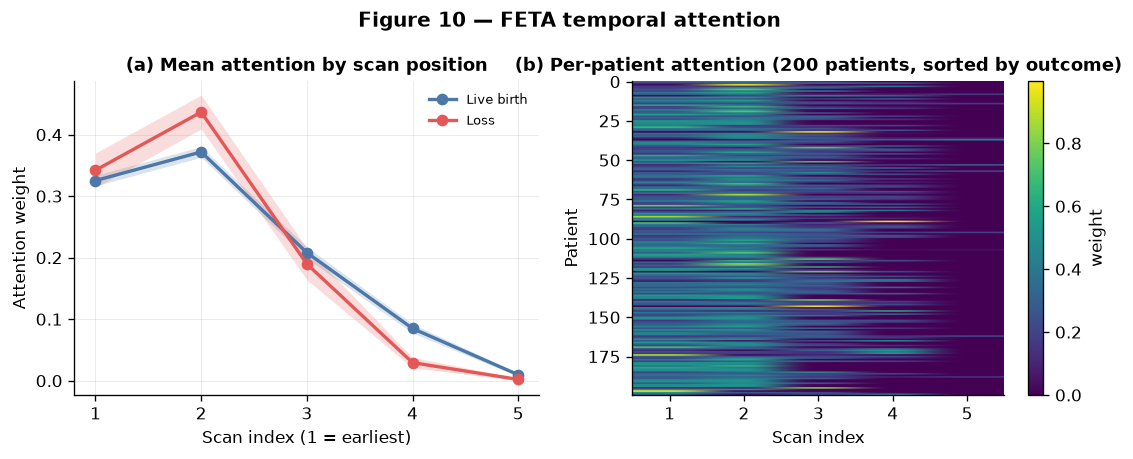

In [22]:
@torch.no_grad()
def collect_temporal_attention(model, loader):
    model.eval()
    A, M, Y = [], [], []
    for b in loader:
        logits, attn = model(b["temporal_features"], b["gestational_ages"],
                             b["temporal_mask"], b["maternal_features"])
        a = attn["temporal_pooling_weights"]          # (B, T) attention-pooling weights
        A.append(a.cpu().numpy()); M.append(b["temporal_mask"].cpu().numpy())
        Y.append(b["label"].cpu().numpy())
    return np.concatenate(A), np.concatenate(M), np.concatenate(Y)

try:
    att, msk, yy = collect_temporal_attention(RESULTS["feta"]["trainer"].model, loaders["test"])
    att = att[:, :msk.shape[1]] * msk                    # zero out padding
    att = att / np.clip(att.sum(1, keepdims=True), 1e-9, None)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    T = att.shape[1]
    x = np.arange(1, T + 1)
    for lab, name, col in [(0, "Live birth", C["live"]), (1, "Loss", C["loss"])]:
        sel = att[yy == lab]
        axes[0].plot(x, sel.mean(0), marker="o", color=col, lw=2, label=name)
        axes[0].fill_between(x, sel.mean(0) - sel.std(0) / np.sqrt(len(sel)),
                             sel.mean(0) + sel.std(0) / np.sqrt(len(sel)),
                             color=col, alpha=.2, lw=0)
    axes[0].set_title("(a) Mean attention by scan position")
    axes[0].set_xlabel("Scan index (1 = earliest)"); axes[0].set_ylabel("Attention weight")
    axes[0].set_xticks(x); axes[0].legend(fontsize=8)

    im = axes[1].imshow(att[np.argsort(yy)][:200], aspect="auto", cmap="viridis")
    axes[1].set_title("(b) Per-patient attention (200 patients, sorted by outcome)")
    axes[1].set_xlabel("Scan index"); axes[1].set_ylabel("Patient")
    axes[1].set_xticks(range(T)); axes[1].set_xticklabels(x)
    axes[1].grid(False)
    plt.colorbar(im, ax=axes[1], label="weight")

    fig.suptitle("Figure 10 — FETA temporal attention", y=1.05, fontsize=12, fontweight="bold")
    fig.savefig(FIGDIR / "fig10_temporal_attention.png")
    plt.show()
except Exception as e:
    print("Temporal attention figure skipped:", e)

### 8.3 Figure 11 — Graph attention (PREG-Net)

Which maternal variable PREG-Net's graph tower weighted most in its readout.

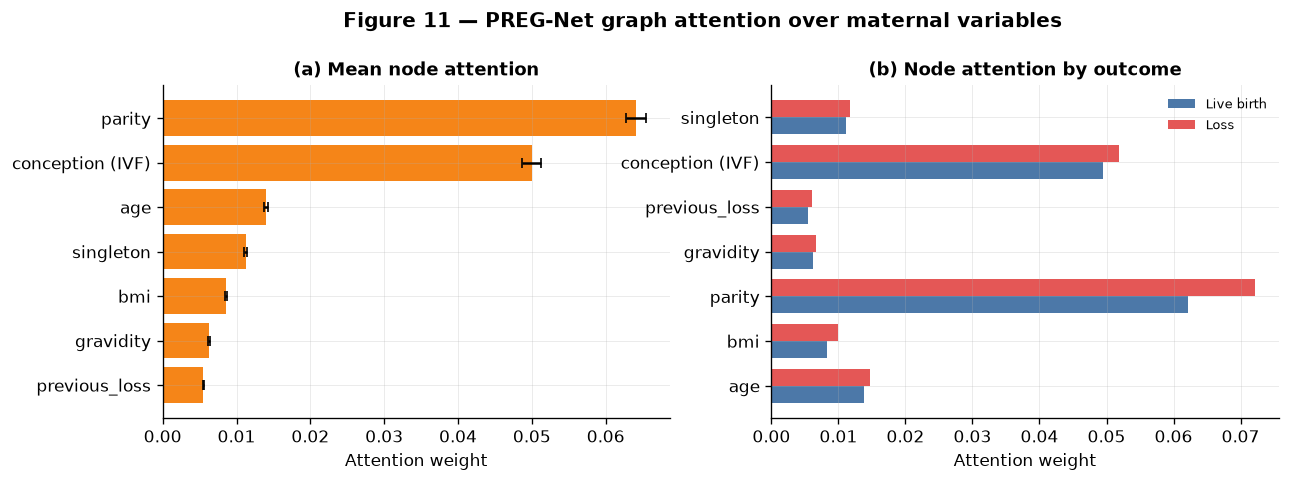

In [23]:
@torch.no_grad()
def collect_node_attention(model, loader, builder):
    model.eval()
    A, Y = [], []
    for b in loader:
        g = builder.batch_to_graph(b)
        logits, attn = model(g["node_features"], g["edge_index"],
                             g["node_types"], g["node_mask"])
        a = attn["node_importance"][:, -7:]          # last 7 nodes = maternal (full graph)
        A.append(a.cpu().numpy()); Y.append(b["label"].cpu().numpy())
    return np.concatenate(A), np.concatenate(Y)

MATERNAL_NODES = ["age", "bmi", "parity", "gravidity", "previous_loss",
                  "conception (IVF)", "singleton"]
try:
    na, ny = collect_node_attention(RESULTS["preg"]["trainer"].model,
                                    loaders["test"], full_graph_builder)
    assert na.shape[1] == len(MATERNAL_NODES), f"node-attention shape {na.shape}"

    order = np.argsort(na.mean(0))
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))

    axes[0].barh([MATERNAL_NODES[i] for i in order], na.mean(0)[order],
                 xerr=na.std(0)[order] / np.sqrt(len(na)),
                 color=C["preg"], capsize=3)
    axes[0].set_title("(a) Mean node attention"); axes[0].set_xlabel("Attention weight")

    w = 0.38
    yv = np.arange(len(MATERNAL_NODES))
    for i, (lab, name, col) in enumerate([(0, "Live birth", C["live"]), (1, "Loss", C["loss"])]):
        axes[1].barh(yv + (i - .5) * w, na[ny == lab].mean(0), height=w, color=col, label=name)
    axes[1].set_yticks(yv); axes[1].set_yticklabels(MATERNAL_NODES)
    axes[1].set_title("(b) Node attention by outcome"); axes[1].set_xlabel("Attention weight")
    axes[1].legend(fontsize=8)

    fig.suptitle("Figure 11 — PREG-Net graph attention over maternal variables",
                 y=1.05, fontsize=12, fontweight="bold")
    fig.savefig(FIGDIR / "fig11_graph_attention.png")
    plt.show()
except Exception as e:
    print("Graph attention figure skipped:", e)

---
## 9. Figure manifest

In [24]:
print("Figures written to", FIGDIR, "\n")
for f in sorted(FIGDIR.glob("*.png")):
    print(f"  {f.name:36s} {f.stat().st_size/1024:7.1f} KB")

paper_table.to_csv(ROOT / "results" / "paper_table_cv.csv")
test_table.to_csv(ROOT / "results" / "paper_table_single_split.csv")
print("\nTables written to results/paper_table_cv.csv, results/paper_table_single_split.csv")

Figures written to c:\Users\sakth\OneDrive\Desktop\Preg-Feta\figures 

  fig10_temporal_attention.png           197.7 KB
  fig11_graph_attention.png              130.2 KB
  fig1_cohort_overview.png               177.3 KB
  fig2_marker_trajectories.png           334.9 KB
  fig3_maternal_risk.png                 174.6 KB
  fig4_architecture.png                  185.5 KB
  fig5_specialist_training.png           219.2 KB
  fig6_roc_pr.png                        211.0 KB
  fig7_cv_auroc.png                      132.0 KB
  fig8_per_fold_delta.png                 69.3 KB
  fig9_gate.png                          267.8 KB

Tables written to results/paper_table_cv.csv, results/paper_table_single_split.csv


---
## 10. Limitations — what this notebook does **not** show

These belong in the manuscript, not just here.

1. **The data is synthetic.** Every number above comes from `synthetic_generator_v2.py`.
   The Kaggle dataset is that generator's output, packaged and published — it is *not* a
   real patient cohort. No claim of clinical validity follows from any result here.

2. **The generator wrote the signal the models recover.** Performance measures how well
   each architecture recovers a *known, injected* signal. It is an upper bound on what
   real data would give, not an estimate of it.

3. **Compare the hybrid against the plain ensemble, not just the specialists.** Under input parity the two
   towers already see the full data, so beating them is not the test. The question that decides
   whether the architecture is worth anything is whether the gated hybrid beats a **simple logit
   average of the same two towers**, and whether it beats an **off-the-shelf gradient-boosted
   tree given all the raw features**. Figure 7 puts all of them on the same axis for exactly this
   reason; the off-the-shelf gradient-boosted-tree / logistic-regression comparison lives
   in `scripts/compare_models.py`. Read both before writing the abstract.

4. **The single-tower-with-both-modalities ablation is built into this notebook now.**
   PREG-Net trains on the full graph (ultrasound + maternal nodes), so §7.3 already reports
   whether the hybrid beats a single tower that sees everything. On this cohort it does **not**
   by more than a fold SD — report that honestly rather than quoting a handicapped specialist gap.